In [6]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge, Lasso, LogisticRegression, SGDClassifier # 이 파트는 반드시 알아둘 것
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  # 다항특성 자동생성, # 정규화클래스
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit는 이진분류함수, softmax는 다중분류함수 => 0~1사이의 숫자로 변환시키는 기능

In [9]:
fish = pd.read_csv('data/fish_logistic.csv')

In [10]:
# 자료 분리
data = fish[fish.columns[1:]].values
label = fish['Species'].values
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [11]:
# 정규화 작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [12]:
# lr = LogisticRegression()
# loss="log_loss" : logistic함수를 쓰겠다는 의미
# max_iter : 10 : 10번 반복
# random_state = 42 : 랜덤선택을 고정(연습할 때, 랜덤으로 변경하면 정확도도 함께 변경이 되어서 고정시킴)
# verbose = 1 : 반복하면서 정보를 보여줌. / 설정하지 않으면 보여주지 않음.
sc = SGDClassifier(loss="log_loss", random_state=42) # logistic함수를 쓰겠다는 의미
train_score = []
test_score = []
# 정답지 필요
classes = np.unique(train_label)
for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))


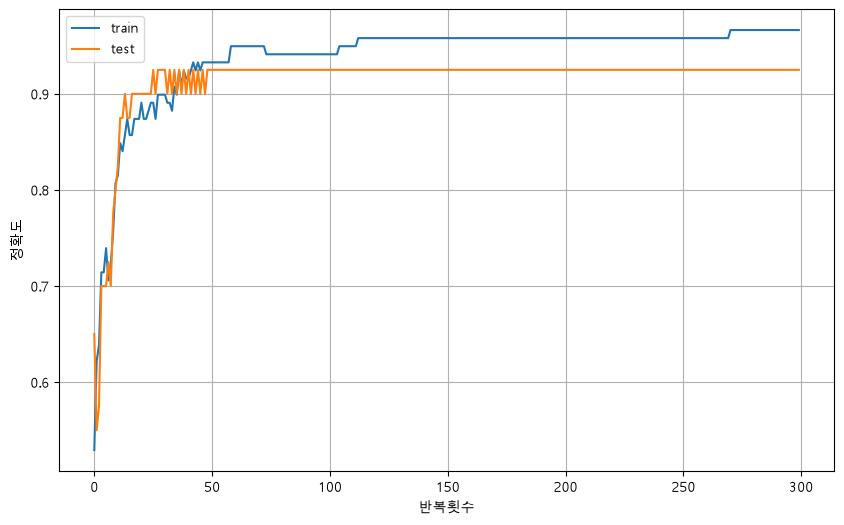

In [13]:
plt.figure(figsize=(10,6))
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.grid()
plt.legend(['train','test'])
plt.show()
# 적합 : 그래프상 정확도가 높으면서 train, test 간의 격차가 가장 작은 100번 횟수가 가장 적합(60~70번부터 가장 적합)

In [14]:
# 첫번째 학습 모형 생성
# tol=None : max_iter가 반복될 때, 일정기간 동안 변동이 없으면 자동으로 중지하는 데 자동중지 해제
sc = SGDClassifier(loss='log_loss',max_iter=100,tol=None) # 가장 적합한 100번을 적용
sc.fit(train_scaled,train_label)
print("train정확도", sc.score(train_scaled,train_label))
print("test정확도", sc.score(test_scaled,test_label))

train정확도 0.8739495798319328
test정확도 0.925


In [15]:
# 동일한 훈련을 반복 -> 추가 학습 진행
# fit : 모든 기울기, 절편을 리셋해서 처음부터 시작
# partial_fit : 현재있는 정보에서 시작
sc.partial_fit(train_scaled,train_label)
print("train정확도:", sc.score(train_scaled,train_label))
print("test정확도:", sc.score(test_scaled,test_label))

train정확도: 0.9411764705882353
test정확도: 0.925


In [16]:
# 분류 : knn, logistic # 의사결정나무
# 예측 : kneighbor regression, Linear Regression 이 많은 비중